# Inferencia - House Pricing

Generación de predicciones de `SalePrice` para el conjunto de prueba a partir de sus datos crudos, usando el modelo `champion` del Model Registry de MLflow (ingeniería de características + modelo). Sus predicciones se comparan con las de los challengers y la ejecución se registra en MLflow. Al final se construye un pipeline de inferencia que integra todo el flujo, desde los datos crudos hasta el precio en dólares, en un único objeto de sklearn.

## 1. Librerías

Importación de las librerías para manipulación de datos, visualización, carga y almacenamiento de modelos, y construcción del pipeline de inferencia, y seguimiento con MLflow.

In [1]:
import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.data
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from mlflow import MlflowClient
from mlflow.models import infer_signature
from scipy.stats import ks_2samp
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from house_pricing.config import (
    CHALLENGER_ALIASES,
    CHAMPION_ALIAS,
    MLFLOW_EXPERIMENT_INFERENCE,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    PROJ_ROOT,
    RAW_DATA_DIR,
    REGISTERED_MODEL_NAME,
    SKOPS_TRUSTED_TYPES,
)
from house_pricing.tracking import configurar_mlflow

C:\Users\MO\anaconda3\envs\env_house_pricing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-10 19:24:31.191 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing


## 2. Carga de configuración y datos crudos de prueba

Lectura de la configuración del pipeline y de `test.csv` sin ningún procesamiento previo. La ruta y el nombre del archivo se definen en variables para poder cambiar la fuente sin modificar el resto del código.

In [2]:
CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"
DATA_PATH = RAW_DATA_DIR
TEST_FILE = "test.csv"
ID_COLUMN = "Id"
REFERENCE_YEAR = "YrSold"

with open(CONFIG_PATH, encoding="utf-8") as f:
    pipeline_config = yaml.safe_load(f)

TARGET = pipeline_config["TARGET"]
INPUT_FEATURES = pipeline_config["MODEL_FEATURES"] + [REFERENCE_YEAR]

test_raw = pd.read_csv(DATA_PATH / TEST_FILE)

print(f"Test: {test_raw.shape}")
print(f"Faltantes en las features de entrada: {test_raw[INPUT_FEATURES].isna().sum().sum()}")

Test: (1459, 80)
Faltantes en las features de entrada: 1297


## 3. Carga del modelo champion desde el Model Registry

Carga del modelo registrado con el alias `champion` en el notebook de entrenamiento. Contiene la ingeniería de características y el modelo ganador ya ajustados con el conjunto de entrenamiento. Se carga por alias y no por número de versión, de modo que siempre se usa el champion vigente.

In [3]:
configurar_mlflow(MLFLOW_EXPERIMENT_INFERENCE)
cliente = MlflowClient()

CHAMPION_URI = f"models:/{REGISTERED_MODEL_NAME}@{CHAMPION_ALIAS}"
version_champion = cliente.get_model_version_by_alias(REGISTERED_MODEL_NAME, CHAMPION_ALIAS)
best_model_pipeline = mlflow.sklearn.load_model(CHAMPION_URI)

print(f"Champion: {REGISTERED_MODEL_NAME} v{version_champion.version} ({version_champion.tags.get('modelo')})")
print(f"RMSE val registrado: {float(version_champion.tags.get('rmse_val')):,.0f}")
best_model_pipeline

Champion: house_pricing_model v1 (GradientBoosting)
RMSE val registrado: 26,425


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,31
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('categorical_imputer', ...), ('numerical_imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See

## 4. Generación de predicciones

Aplicación del pipeline a las features de entrada de los datos crudos de prueba. El modelo predice en escala `log1p`, por lo que las predicciones se revierten con `np.expm1` para obtener `SalePrice` en dólares.

In [4]:
pred_log = best_model_pipeline.predict(test_raw[INPUT_FEATURES])
pred_saleprice = np.expm1(pred_log)

predicciones = pd.DataFrame({ID_COLUMN: test_raw[ID_COLUMN], TARGET: pred_saleprice})

print(f"Predicciones: {len(predicciones)} | Faltantes: {predicciones[TARGET].isna().sum()}")
predicciones[TARGET].describe().round(0).to_frame().T

Predicciones: 1459 | Faltantes: 0


,count,mean,std,min,25%,50%,75%,max
SalePrice,1459.0,177203.0,75526.0,43874.0,127711.0,156784.0,206097.0,533158.0


## 5. Exportación de predicciones

Almacenamiento de las predicciones en `data/processed/predictions.csv` con las columnas `Id` y `SalePrice`, el mismo formato de `sample_submission.csv`.

In [5]:
PREDICTIONS_OUTPUT = PROCESSED_DATA_DIR / "predictions.csv"

predicciones.to_csv(PREDICTIONS_OUTPUT, index=False)

print(f"Guardado: {PREDICTIONS_OUTPUT}")
predicciones.head()

Guardado: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing\data\processed\predictions.csv


,Id,SalePrice
0,1461,124070.474249
1,1462,151519.963546
2,1463,184004.651006
3,1464,187687.950419
4,1465,193981.841776


## 6. Pipeline de inferencia

Integración de todo el flujo de inferencia en un único `Pipeline` de sklearn, que recibe el dataset crudo completo y devuelve `SalePrice` en dólares:

1. **`feature_selector`** (`ColumnTransformer`): conserva solo las features de entrada del modelo, en el mismo orden con el que se entrenó, y descarta el resto de columnas, incluido `Id`. La salida se mantiene como `DataFrame` para que los transformadores de `feature-engine` identifiquen las variables por nombre.
2. **`regressor`** (`TransformedTargetRegressor`): envuelve el pipeline del modelo champion (ingeniería de características + modelo) y aplica `log1p` al target al entrenar y `expm1` a la predicción.

Como `TransformedTargetRegressor` debe ajustarse para quedar operativo, se entrena con el mismo 80% de entrenamiento y los mismos hiperparámetros del modelo ganador (`TEST_SIZE` y `RANDOM_STATE` deben coincidir con los notebooks anteriores). El resultado es equivalente al modelo ganador, lo que se verifica comparando sus predicciones con las de la sección 4.

In [6]:
TRAIN_FILE = "train.csv"

# Deben coincidir con los notebooks 2.0 y 3.0
TEST_SIZE = 0.2
RANDOM_STATE = 42

train_raw = pd.read_csv(DATA_PATH / TRAIN_FILE)
X_train_raw, _, y_train_real, _ = train_test_split(
    train_raw.drop(columns=TARGET), train_raw[TARGET], test_size=TEST_SIZE, random_state=RANDOM_STATE
)

feature_selector = ColumnTransformer(
    transformers=[("input_features", "passthrough", INPUT_FEATURES)],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

inference_pipeline = Pipeline(steps=[
    ("feature_selector", feature_selector),
    ("regressor", TransformedTargetRegressor(
        regressor=clone(best_model_pipeline),
        func=np.log1p,
        inverse_func=np.expm1,
    )),
])

inference_pipeline.fit(X_train_raw, y_train_real)

pred_pipeline = inference_pipeline.predict(test_raw)
print(f"Predicciones idénticas a la sección 4: {np.allclose(pred_pipeline, pred_saleprice)}")
print(f"Diferencia máxima: {np.abs(pred_pipeline - pred_saleprice).max():.6f}")
inference_pipeline

Predicciones idénticas a la sección 4: True
Diferencia máxima: 0.000000


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_selector', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](80,)","['Id','MSSubClass','MSZoning',...,'YrSold','SaleType','SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,80
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('input_features', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature na

## 7. Almacenamiento y uso del pipeline de inferencia

Almacenamiento del pipeline de inferencia en `models/inference_pipeline.pkl` y ejemplo de uso: se carga y se aplica directamente sobre los datos crudos de prueba, sin pasos adicionales.

In [7]:
INFERENCE_PIPELINE_PATH = MODELS_DIR / "inference_pipeline.pkl"

joblib.dump(inference_pipeline, INFERENCE_PIPELINE_PATH)
print(f"Guardado: {INFERENCE_PIPELINE_PATH}")

pipeline_cargado = joblib.load(INFERENCE_PIPELINE_PATH)
pd.DataFrame({ID_COLUMN: test_raw[ID_COLUMN], TARGET: pipeline_cargado.predict(test_raw)}).head()

Guardado: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clase\House_pricing\models\inference_pipeline.pkl


,Id,SalePrice
0,1461,124070.474249
1,1462,151519.963546
2,1463,184004.651006
3,1464,187687.950419
4,1465,193981.841776


## 8. Comparación de distribuciones: train vs predicciones

Densidad de `SalePrice` real en el dataset de entrenamiento (`train.csv` completo) frente a la densidad de `SalePrice` producido por el pipeline de inferencia sobre los datos de prueba. Distribuciones similares indican que las predicciones son coherentes con los precios observados; diferencias en las colas muestran los rangos de precio que el modelo tiende a comprimir o exagerar.

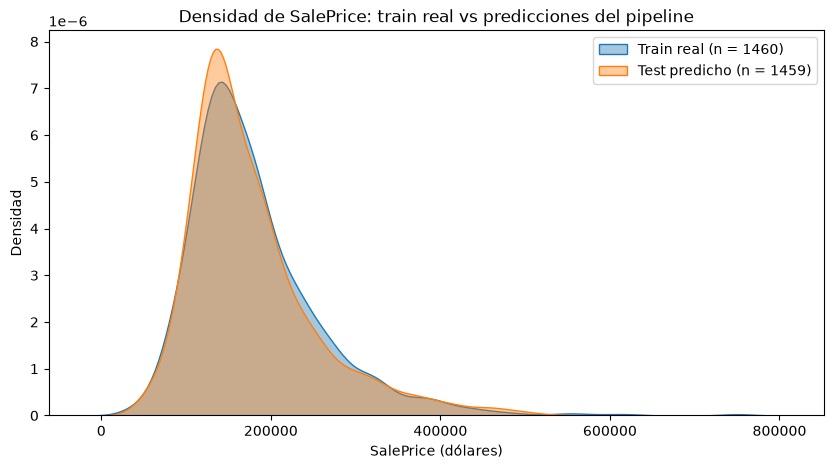

,count,mean,std,min,25%,50%,75%,max
train_real,1460.0,180921.0,79443.0,34900.0,129975.0,163000.0,214000.0,755000.0
test_predicho,1459.0,177203.0,75526.0,43874.0,127711.0,156784.0,206097.0,533158.0


In [8]:
pred_test = pipeline_cargado.predict(test_raw)

fig_densidad, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(x=train_raw[TARGET], fill=True, alpha=0.4, label=f"Train real (n = {len(train_raw)})", ax=ax)
sns.kdeplot(x=pred_test, fill=True, alpha=0.4, label=f"Test predicho (n = {len(pred_test)})", ax=ax)
ax.set_title(f"Densidad de {TARGET}: train real vs predicciones del pipeline")
ax.set_xlabel(f"{TARGET} (dólares)")
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

pd.DataFrame({
    "train_real": train_raw[TARGET].describe(),
    "test_predicho": pd.Series(pred_test).describe(),
}).round(0).T

## 9. Comparación con los challengers

Predicciones de los modelos con alias `challenger_1` y `challenger_2` sobre los mismos datos de prueba, en modo sombra: no se exportan, solo se comparan con las del champion. Para cada modelo se reporta:

- `rmse_val_registrado`: RMSE en validación con el que se registró en el torneo.
- `media` y `mediana` de `SalePrice` predicho.
- `dif_rel_vs_champion`: diferencia relativa media absoluta frente a las predicciones del champion.
- `correlacion_vs_champion`: correlación de Pearson con las predicciones del champion.
- `ks_vs_train`: estadístico de Kolmogorov-Smirnov contra `SalePrice` real de entrenamiento (menor es más parecido).

In [9]:
versiones = {CHAMPION_ALIAS: version_champion}
predicciones_modelos = {CHAMPION_ALIAS: pred_saleprice}

for alias in CHALLENGER_ALIASES:
    versiones[alias] = cliente.get_model_version_by_alias(REGISTERED_MODEL_NAME, alias)
    challenger = mlflow.sklearn.load_model(f"models:/{REGISTERED_MODEL_NAME}@{alias}")
    predicciones_modelos[alias] = np.expm1(challenger.predict(test_raw[INPUT_FEATURES]))

comparacion = pd.DataFrame([
    {
        "alias": alias,
        "modelo": versiones[alias].tags.get("modelo"),
        "version": versiones[alias].version,
        "rmse_val_registrado": float(versiones[alias].tags.get("rmse_val")),
        "media": pred.mean(),
        "mediana": np.median(pred),
        "dif_rel_vs_champion": np.mean(np.abs(pred - pred_saleprice) / pred_saleprice),
        "correlacion_vs_champion": np.corrcoef(pred, pred_saleprice)[0, 1],
        "ks_vs_train": ks_2samp(pred, train_raw[TARGET]).statistic,
    }
    for alias, pred in predicciones_modelos.items()
])

comparacion.style.format({
    "rmse_val_registrado": "{:,.0f}", "media": "{:,.0f}", "mediana": "{:,.0f}",
    "dif_rel_vs_champion": "{:.2%}", "correlacion_vs_champion": "{:.4f}", "ks_vs_train": "{:.4f}",
})

,alias,modelo,version,rmse_val_registrado,media,mediana,dif_rel_vs_champion,correlacion_vs_champion,ks_vs_train
0,champion,GradientBoosting,1,"26,425","177,203","156,784",0.00%,1.0000,0.0449
1,challenger_1,RandomForest,2,"27,076","176,291","156,341",4.52%,0.9898,0.0524
2,challenger_2,MLP,3,"28,914","179,046","159,196",6.11%,0.9799,0.0284


## 10. Registro de la inferencia en MLflow

Cada ejecución de este notebook se registra como un run en el experimento `house_pricing_inferencia`, vinculado a la versión del champion utilizada:

- **Parámetros y tags**: URI y versión del champion, run de entrenamiento que lo originó, archivo de prueba y número de predicciones.
- **Dataset**: `test.csv` como entrada de inferencia.
- **Métricas**: estadísticas de las predicciones, predicciones inválidas, porcentaje fuera del rango de `SalePrice` de entrenamiento, KS contra train y diferencia relativa frente a cada challenger.
- **Artefactos**: `predictions.csv`, tabla de comparación con los challengers, gráfica de densidades y el pipeline de inferencia como modelo de MLflow.

In [10]:
target_train = train_raw[TARGET]
columnas_enteras = test_raw.select_dtypes("integer").columns
test_firma = test_raw.astype({col: "float64" for col in columnas_enteras})

with mlflow.start_run(run_name=f"inferencia_{CHAMPION_ALIAS}_v{version_champion.version}") as run_inferencia:
    mlflow.set_tags({
        "champion_version": version_champion.version,
        "champion_modelo": version_champion.tags.get("modelo"),
        "champion_run_id": version_champion.run_id,
    })
    mlflow.log_params({
        "modelo_registrado": REGISTERED_MODEL_NAME,
        "champion_uri": CHAMPION_URI,
        "champion_version": version_champion.version,
        "archivo_prueba": TEST_FILE,
        "n_predicciones": len(pred_test),
    })
    mlflow.log_input(
        mlflow.data.from_pandas(test_raw, source=str(DATA_PATH / TEST_FILE), name=TEST_FILE),
        context="inference",
    )
    mlflow.log_metrics({
        "pred_media": pred_test.mean(),
        "pred_mediana": np.median(pred_test),
        "pred_std": pred_test.std(),
        "pred_min": pred_test.min(),
        "pred_max": pred_test.max(),
        "pred_invalidas": int((~np.isfinite(pred_test) | (pred_test <= 0)).sum()),
        "pct_fuera_rango_train": np.mean((pred_test < target_train.min()) | (pred_test > target_train.max())),
        "ks_vs_train": ks_2samp(pred_test, target_train).statistic,
    })
    for fila in comparacion.iloc[1:].itertuples():
        mlflow.log_metric(f"dif_rel_vs_{fila.alias}", fila.dif_rel_vs_champion)

    mlflow.log_artifact(str(PREDICTIONS_OUTPUT), artifact_path="predicciones")
    mlflow.log_table(comparacion, artifact_file="challengers/comparacion.json")
    mlflow.log_figure(fig_densidad, "graficas/densidad_train_vs_predicciones.png")
    mlflow.sklearn.log_model(
        pipeline_cargado,
        name="inference_pipeline",
        signature=infer_signature(test_firma, pred_test),
        input_example=test_firma.head(5),
        skops_trusted_types=SKOPS_TRUSTED_TYPES,
    )

print(f"Run de inferencia: {run_inferencia.info.run_id}")

Run de inferencia: e4031a5b8a9d4e7bab5afaa147ecb1ee
